In [1]:
# Colab T4 에서 약 50초 걸립니다
import os, re, time
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # 맥(ARM)과 Colab(x86)에서 Kiwi 결과를 같게
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그림의 한글 글꼴
import torch
import bertopic
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from kiwipiepy import Kiwi
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score

pd.set_option("display.max_colwidth", 90)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("장치:", device, "| bertopic", bertopic.__version__)

c:\Users\pyostry\.conda\envs\myenv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


장치: cpu | bertopic 0.17.4


In [2]:
BASE = "https://huggingface.co/api/datasets/heegyu/korean-petitions/parquet/default/train/"
COLS = ["title", "content", "category", "begin", "num_agree"]
IN_2018 = [("begin", ">=", pd.Timestamp("2019-01-01")), ("begin", "<", pd.Timestamp("2020-01-01"))]

t0 = time.time()
raw = pd.concat([pd.read_parquet(BASE + f"{i}.parquet", columns=COLS, filters=IN_2018)
                 for i in (0, 1)], ignore_index=True)
print(f"2019년 청원 {len(raw):,}건, {time.time() - t0:.0f}초")

2019년 청원 66,788건, 23초


In [3]:
PII_PATTERNS = [
    r"(?<=저는 )[가-힣]{2,4}?(?=입니다)",                  # 「저는 홍길동입니다」
    r"[가-힣]{2,4}?(?=(?:이)?라고 ?합니다)",                # 「홍길동이라고 합니다」
    r"0\d{1,2}[-. ]?\d{3,4}[-. ]?\d{4}",                # 전화번호(010-1234-5678, 02-123-4567)
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",    # 이메일
    r"\d{6}[- ]?[1-4]\d{6}",                            # 주민등록번호 꼴
]
PII_RE = re.compile("|".join(PII_PATTERNS))

def mask(text, n=80):
    text = PII_RE.sub(lambda m: "○" * len(m.group()), str(text))
    return text if len(text) <= n else text[:n] + "…"

print(mask("예로 만든 문장: 저는 홍길동이라고 합니다. 연락처는 010-1234-5678 입니다"))
raw.sample(3, random_state=1).assign(title=lambda d: d["title"].map(mask), content=lambda d: d["content"].map(mask))

예로 만든 문장: 저는 ○○○이라고 합니다. 연락처는 ○○○○○○○○○○○○○ 입니다


,title,content,category,begin,num_agree
44547,"미세먼지 외교 노력, 종전선언만큼 급하다",말 안해도 다 알지 않냐?,외교/통일/국방,2019-03-05,10
9553,미세먼지 우린어디로 가란 건가요?,미세먼지가 많은 여기 한국입니다 성인이 다녀도 다음날이면 목이칼칼해지는데 노인분들과 유아들은 어떻게 하란건가요? 정부님께서 어떤 비상조치를 문자…,안전/환경,2019-01-15,25
9975,2019년 기업인과의 대화,저는 오늘 2019년 문재인대통령님께서 기업인과의 대화의 시간을 보게 되었습니다. 역대 어느 정부 보다도 국민을 향한 낮은 자세를 취하려고 하는…,기타,2019-01-15,0


In [4]:
steps = {"2019년 청원": len(raw)}
df = raw[raw["content"].fillna("").str.strip() != ""]
steps["본문이 빈 청원 제외"] = len(df)
df = df.drop_duplicates(["title", "content"]).reset_index(drop=True)
steps["중복 청원 제외"] = len(df)

MAX_LEN = 150
df["doc"] = ((df["title"].fillna("") + " " + df["content"])
             .str.replace(r"\s+", " ", regex=True).str.strip().str.slice(0, MAX_LEN))
pd.Series(steps, name="청원 수").to_frame()

,청원 수
2019년 청원,66788
본문이 빈 청원 제외,66751
중복 청원 제외,65374


In [5]:
N_SAMPLE = 10_000
sample = df.sample(n=N_SAMPLE, random_state=0)
new = df.drop(sample.index).sample(n=500, random_state=1).reset_index(drop=True)
sample = sample.reset_index(drop=True)

print("학습 표본:", len(sample), "| 새 청원:", len(new))
print(f"동의 100 이상인 청원: {(sample['num_agree'] >= 100).mean():.1%}")
sample["begin"].dt.month.value_counts().sort_index().rename("청원 수").to_frame().T

학습 표본: 10000 | 새 청원: 500
동의 100 이상인 청원: 8.4%


begin,1,2,3,4,5,6,7,8
청원 수,3078,2939,3506,70,101,92,103,111


In [6]:
EMB_PATH = f"emb_kure_n{len(sample)}_l{MAX_LEN}.npy"

emb_model = SentenceTransformer("nlpai-lab/KURE-v1", device=device)
emb_model.max_seq_length = 256
if device == "cuda":
    emb_model.half()  # 16비트 실수로 계산

if os.path.exists(EMB_PATH):
    emb = np.load(EMB_PATH)
    print("저장된 임베딩을 불러왔습니다:", EMB_PATH, emb.shape)
else:
    t0 = time.time()
    emb = emb_model.encode(sample["doc"].tolist(), batch_size=64,
                           normalize_embeddings=True, show_progress_bar=True)
    emb = np.asarray(emb, dtype=np.float32)
    np.save(EMB_PATH, emb)
    print(f"인코딩 {time.time() - t0:.0f}초, 모양 {emb.shape}, 저장 {EMB_PATH}")

emb_new = np.asarray(emb_model.encode(new["doc"].tolist(), normalize_embeddings=True), dtype=np.float32)

Loading weights: 100%|██████████| 391/391 [00:01<00:00, 286.43it/s]


저장된 임베딩을 불러왔습니다: emb_kure_n10000_l150.npy (10000, 1024)


In [8]:
docs = sample["doc"].tolist()

t0 = time.time()
base_model = BERTopic()
base_topics, _ = base_model.fit_transform(docs, embeddings = emb)
n_base = len(set(base_topics)) - 1
print(f"토픽 {n_base}개 | 이상치 {np.mean(np.array(base_topics) == -1):.1f} | {time.time() - t0:.0f}초")
base_model.get_topic_info().head(6)[["Topic", "Count", "Name"]]

토픽 138개 | 이상치 0.3 | 21초


,Topic,Count,Name
0,-1,3274,-1_18_200_10_625
1,0,470,0_max_613_20190221_1910
2,1,297,1_mri_equalityfamily_of_263000
3,2,288,2_098_10000000000_1350_15771000
4,3,283,3_816_cgv_411_2006
5,4,227,4_vpn_2021_posco_ytn


In [11]:
example = docs [45]
print("원문 :", mask(example, 70))
print("처리한 뒤:", re.sub(r"[^A-Za-z0-9 ]+", "", example).split())

원문 : 자유한국당과 조선일보의 미세먼지 공포마케팅 금지시켜주세요! 뭔가 부풀려서 반정부 분위기를 형성하는 것이 보여요! 한마디 해주세…
처리한 뒤: []


In [15]:
kiwi = Kiwi()

def nouns(texts):
    return [" ".join(t.form for t in toks if t.tag in ("NNG", "NNP")) for toks in kiwi.tokenize(texts)]

t0 = time.time()
sample["nouns"] = nouns(sample["doc"].tolist())
new["nouns"] = nouns(new["doc"].tolist())
print(f"Kiwi 명사 추출 {time.time() - t0:.0f}초")
sample[["doc", "nouns"]].head(3).map(mask)

Kiwi 명사 추출 4초


,doc,nouns
0,"국민이 바라는 사법개혁안의 입법과 대법관들의 위헌적인 불법행위에 대한 진상조사를 청원함 저는 ,아래에 링크된 글에서 보시는 바와같이 , 국민의 …",국민 사법 개혁 안 입법 법관 위헌 불법 행위 진상 조사 청원 아래 링크 글 국민 사람 대표 국민 법원 홈페이지 법원 공간 김명수 대법원장 국민
1,"서민들에게 물가폭등 세금인상할생각 그만해라 적폐대상 정부는 세금인상하여 누구에게 줄려고 세금인상할생각뿐인가 다음선거에서 두고봐라,,,서민들다죽이…",서민 물가 폭등 세금 인상 생각 적폐 대상 정부 세금 인상 세금 인상 생각 다음 선거 서민 나라 꼴 개판
2,●꼭 보세요 미래는 없다 * 영상 꼭 보세요,미래 영상


In [16]:
STOP_WORDS = ["것", "수", "등", "때", "거", "중", "년", "월", "일", "분", "번", "개", "명", "곳",
              "데", "점", "뭐", "좀", "청원", "국민", "대통령", "생각", "부탁"]
vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                             stop_words=STOP_WORDS)
docs_nouns = sample["nouns"].tolist()

In [17]:
def summary(lab):
    sizes = pd.Series(lab[lab != -1]).value_counts()
    return {"토픽 수": len(sizes), "이상치 %": round((lab == -1).mean() * 100, 1),
            "가장 큰 토픽 %": round(sizes.iloc[0] / len(lab) * 100, 1)}

reduced_nn, rows = {}, []
for nn in (5, 15, 50):
    t0 = time.time()
    reduced_nn[nn] = UMAP(n_neighbors=nn, n_components=5, min_dist=0.0, metric="cosine",
                          random_state=0).fit_transform(emb)
    lab = HDBSCAN(min_cluster_size=50).fit(reduced_nn[nn]).labels_
    rows.append({"n_neighbors": nn, **summary(lab), "UMAP 초": round(time.time() - t0)})
pd.DataFrame(rows)

,n_neighbors,토픽 수,이상치 %,가장 큰 토픽 %,UMAP 초
0,5,35,25.4,14.1,9
1,15,30,28.9,7.0,11
2,50,33,36.6,6.3,19


In [18]:
rows = []
for ms in (None, 10, 1):
    lab = HDBSCAN(min_cluster_size=50, min_samples=ms).fit(reduced_nn[15]).labels_
    rows.append({"min_samples": "기본(50)" if ms is None else ms, **summary(lab)})
pd.DataFrame(rows)

,min_samples,토픽 수,이상치 %,가장 큰 토픽 %
0,기본(50),30,28.9,7.0
1,10,43,26.5,6.7
2,1,56,25.3,6.3


In [19]:
umap_args = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine")

reduced = {0: reduced_nn[15]}
for seed in (1, 2):
    t0 = time.time()
    reduced[seed] = UMAP(**umap_args, random_state=seed).fit_transform(emb)
    print(f"UMAP 시드 {seed}: {time.time() - t0:.0f}초")

UMAP 시드 1: 12초
UMAP 시드 2: 11초


In [20]:
rows, labels_grid = [], {}
for mcs in (30, 50, 100):
    for seed in (0, 1, 2):
        lab = HDBSCAN(min_cluster_size=mcs, prediction_data=True).fit(reduced[seed]).labels_
        labels_grid[(mcs, seed)] = lab
        rows.append({"최소 군집 크기": mcs, "시드": seed, **summary(lab)})
grid = pd.DataFrame(rows)
grid

,최소 군집 크기,시드,토픽 수,이상치 %,가장 큰 토픽 %
0,30,0,56,31.5,6.7
1,30,1,56,32.8,7.0
2,30,2,57,30.4,6.6
3,50,0,30,28.9,7.0
4,50,1,30,30.4,6.8
5,50,2,31,33.4,6.3
6,100,0,22,36.2,6.6
7,100,1,22,35.1,6.9
8,100,2,22,36.3,6.9


In [21]:
print("배정 1 대 배정 2:", adjusted_rand_score([0, 0, 1, 1], [5, 5, 2, 2]))
print("배정 1 대 배정 3:", adjusted_rand_score([0, 0, 1, 1], [5, 2, 5, 2]))

배정 1 대 배정 2: 1.0
배정 1 대 배정 3: -0.5


In [22]:
topic_model = BERTopic(
    language="multilingual",
    embedding_model=emb_model,
    umap_model=UMAP(**umap_args, random_state=0),
    hdbscan_model=HDBSCAN(min_cluster_size=50, metric="euclidean",
                          cluster_selection_method="eom", prediction_data=True),
    vectorizer_model=vectorizer,
)
t0 = time.time()
topics, probs = topic_model.fit_transform(docs_nouns, embeddings=emb)
sample["topic"], sample["prob"] = topics, probs
print(f"토픽 {len(set(topics)) - 1}개 | 이상치 {np.mean(np.array(topics) == -1):.1%} | {time.time() - t0:.0f}초")
print("위 표의 시드 0 · 최소 군집 크기 50 과 같은 배정인가(ARI):",
      round(adjusted_rand_score(topics, labels_grid[(50, 0)]), 3))

토픽 30개 | 이상치 28.9% | 12초
위 표의 시드 0 · 최소 군집 크기 50 과 같은 배정인가(ARI): 1.0


In [23]:
topic_model.get_topic_info().head(10)[["Topic", "Count", "Name"]]

,Topic,Count,Name
0,-1,2890,-1_사람_나라_먼지_미세
1,0,701,0_미세_사람_먼지_안녕
2,1,657,1_먼지_미세_사람_말
3,2,607,2_미세_먼지_사람_나라
4,3,597,3_사람_대한민국_말_나라
5,4,384,4_사람_말_의원_차
6,5,367,5_정부_사람_문재인_청년
7,6,319,6_말_사람_여성_문재인
8,7,285,7_사람_여성_미세_먼지
9,8,278,8_나라_미세_먼지_사람


In [29]:
def find_topic(*words, n=10):
    best, best_score = None, (0, 0)
    for t in sorted(set(topic_model.topics_) - {-1}):
        top = [w for w, _ in topic_model.get_topic(t)[:n]]
        hits = [top.index(w) for w in words if w in top]
        score = (len(hits), -min(hits)) if hits else (0, 0)
        if hits and score > best_score:
            best, best_score = t, score
    if best is None:
        print(f"이 실행에서는 「{' · '.join(words)}」 토픽이 나오지 않았습니다.")
        print("위 토픽 표에서 비슷한 토픽 번호를 골라, 이 셀의 find_topic(...) 을 그 번호로 바꿔 실행합니다.")
    return best

def top_words(t, aspect=None, n=6):
    pairs = topic_model.get_topic(t) if aspect is None else topic_model.topic_aspects_[aspect][t]
    return " · ".join(w for w, _ in pairs[:n])

t_probe = find_topic("먼지", "건강")
t_drunk = find_topic("문재인", "북한")
for t in (t_probe, t_drunk):
    if t is not None:
        print(f"고치기 전 토픽 {t}:", top_words(t, n=10))

고치기 전 토픽 1: 먼지 · 미세 · 사람 · 말 · 나라 · 조사 · 정부 · 대한민국 · 국가 · 법
고치기 전 토픽 21: 문재인 · 방안 · 대표 · 공예 · 대한민국 · 말 · 적산 · 요양 · 정신 · 전통


In [30]:
# Colab T4 에서 약 40초 걸립니다(명사를 다시 추출)
kiwi.add_user_word("미세먼지", "NNP")
sample["nouns"] = nouns(sample["doc"].tolist())
new["nouns"] = nouns(new["doc"].tolist())
docs_nouns = sample["nouns"].tolist()

topic_model.update_topics(docs_nouns, vectorizer_model=vectorizer)
for t in (t_probe, t_drunk):
    if t is not None:
        print(f"고친 뒤   토픽 {t}:", top_words(t, n=10))

고친 뒤   토픽 1: 사람 · 말 · 미세먼지 · 나라 · 조사 · 정부 · 대한민국 · 국가 · 법 · 문재인
고친 뒤   토픽 21: 문재인 · 방안 · 대표 · 공예 · 대한민국 · 말 · 적산 · 요양 · 정신 · 전통


In [31]:
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance

t0 = time.time()
topic_model.update_topics(
    docs_nouns, vectorizer_model=vectorizer,
    representation_model={"KeyBERT": KeyBERTInspired(random_state=0),
                          "MMR": MaximalMarginalRelevance(diversity=0.3)})
print(f"{time.time() - t0:.0f}초")

pd.DataFrame([{"토픽": t, "c-TF-IDF": top_words(t), "KeyBERTInspired": top_words(t, "KeyBERT"),
               "MMR": top_words(t, "MMR")} for t in range(8)])

38초


,토픽,c-TF-IDF,KeyBERTInspired,MMR
0,0,사람 · 안녕 · 나라 · 의원 · 미세먼지 · 대한민국,미세먼지 · 사람 · 요즘 · 먼지 · 정부 · 내용,사람 · 안녕 · 나라 · 의원 · 미세먼지 · 문재인
1,1,사람 · 말 · 미세먼지 · 나라 · 조사 · 정부,미세먼지 · 먼지 · 요즘 · 담배 · 국회의원 · 사람,사람 · 미세먼지 · 조사 · 문재인 · 공무원 · 국회
2,2,사람 · 미세먼지 · 나라 · 문제 · 정부 · 말,미세먼지 · 먼지 · 정부 · 대책 · 요즘 · 사람,사람 · 미세먼지 · 문재인 · 세금 · 아파트 · 국회
3,3,사람 · 대한민국 · 말 · 나라 · 의원 · 법,반대 · 폐지 · 처벌 · 국회 · 사람 · 정책,사람 · 법 · 세금 · 문재인 · 반대 · 국회
4,4,사람 · 말 · 의원 · 차 · 돈 · 나라,미세먼지 · 세금 · 가격 · 사람 · 돈 · 정부,세금 · 여자 · 법 · 생리대 · 교복 · 미세먼지
5,5,정부 · 사람 · 문재인 · 청년 · 나라 · 버스,미세먼지 · 사람 · 대책 · 요즘 · 문제 · 먼지,정부 · 문재인 · 버스 · 의원 · 미세먼지 · 세금
6,6,말 · 사람 · 여성 · 문재인 · 안녕 · 반대,요즘 · 미세먼지 · 지원 · 가능 · 투기 · 처벌,여성 · 문재인 · 반대 · 폐지 · 학교 · 지금
7,7,사람 · 여성 · 말 · 이상 · 회사 · 대한민국,미세먼지 · 먼지 · 요즘 · 대책 · 차별 · 이유,대한민국 · 미세먼지 · 주차 · 요즘 · 이유 · 세금


In [33]:
def read_topic(t, seed=0):
    sub = sample[sample["topic"] == t]
    rep = sub[sub["nouns"].isin(topic_model.get_representative_docs(t))].head(3)
    rnd = sub.drop(rep.index).sample(5, random_state=seed)
    edge = sub.drop(rep.index.union(rnd.index)).nsmallest(2, "prob")
    out = pd.concat([rep.assign(kind="대표"), rnd.assign(kind="무작위"), edge.assign(kind="경계")])
    return pd.DataFrame({"종류": out["kind"], "소속 확률": out["prob"].round(2), "청원": out["doc"].map(mask)})

t = find_topic("미세먼지", "버스", "도둑")
if t is not None:
    print(f"토픽 {t}:", top_words(t, n=8))
read_topic(t) if t is not None else None

토픽 12: 미세먼지 · 정부 · 연금 · 대한민국 · 사람 · 국가 · 말 · 아파트


,종류,소속 확률,청원
5287,대표,0.98,"국민연금=공무원연금,군인연금,사학연금통합시켜라 국민세금 도둑질하지마라.똑같이 내고 똑같이 받자 국민연금=공무원연금,군인연금,사학연금통합시켜라 국…"
9263,무작위,0.78,장보러온 손님을 정신병자 도둑으로 만든 이마트 커뮤니티게시판에 올라온 글입니다. 그냥 묻히기에는 아까운사건이라 청원게시판에 올립니다. 이마트가 …
1997,무작위,0.79,자동차 매연을 없애는 물질 개발 저는 합천에 살고 있는. 윤주흥 입니다. 수냉식의 엔진에서 니오는 매연을 없애는 물질을 발견하고도 어찌해야할지를…
4571,무작위,0.76,서민의 삶이 최악인 지금 세금을 얼마나 더 걷어 뭘 어떻게 하겠다고 진짜 못 살겠다~ 나이 먹어 집 한체 갖고 있는 것도 죄가 되는 지금의 실정…
7887,무작위,0.75,여성가족부 진선미 장관을 내란선동죄로 체포해 주세요. 워마드라는 이름으로 혜화역 여성과격시위를 벌이고 있는 배후세력과 그 실체가 여성가족부인 게…
7116,무작위,0.54,아파트가격잡기 제안 드립니다 최근 불과 1~2년 만에 아파트가격 너무많이 급등 하였습니다. 실예로 1년반정도 거래가격 40평가격이 4억5천 이었…
929,경계,0.31,미세먼저 해결해주십쇼 서울거주하는 30대 청년입니다. 미세먼지가 날이 갈수록 심해지고있는데 깜깜 무소식이네요. 매일 아침 하루의 시작을 미세먼지…
6028,경계,0.32,청소년 화장품 소지와 화장하는 것을 허락해주세요 솔직히 학생은 학생다워야 이쁘다는 말이 왜 생겼는지 잘 모르겠습니다. 학생이면 공부나 열심히 하…


In [34]:
t = find_topic("게시판", "청와대", "답변")
if t is not None:
    print(f"토픽 {t}:", top_words(t, n=8))
read_topic(t) if t is not None else None

토픽 19: 사람 · 아파트 · 사건 · 뉴스 · 확인 · 문재인 · 면허 · 법


,종류,소속 확률,청원
983,대표,0.68,언론에 개입을 멈춰주세요 요즘 연예인들의 행동에 대한 기사와 뉴스가 많이 올라오고있습니다 큰사건 부터 작은사건까지 하지만 이사건들에는 한가지 공…
2083,대표,0.77,사회중요이슈 연예인기사로 덮으려는 사람들 처벌해주세요 김학의별장성접대.장자연사건.버닝썬으로 본 정경유착. 마약.성접대.탈세.북미 북핵문제. 협상…
7393,대표,0.93,"집(아파트)포함해서 3채이상되는사람은 못가지고있게하는법이필요합니다. 집(아파트)포함해서 3채이상은 보유를못하게해야합니다. 집이나,아파트를 월세,…"
3833,무작위,0.68,개 아작 초읽기 들어간 아파트(부동산 시장)............. 아파트 개 아작 초읽기 들어갑니다 문재인 정부는 심각하게 인식하고 대책을 세…
7051,무작위,1.00,"어린이집 평가인증 폐지 청원합니다 평가인증폐지 청원합니다. 관찰자자 마다 잣대도 다르고 그날의 원분위기,아이들, 관찰자의 켠디션에 따라 점수도 …"
7160,무작위,0.75,"아토피 치료제 '듀피젠트'의 보험적용화, 보급화를 요청합니다 6살 여아를 키우는 엄마입니다 생후 50일부터 시작한 아토피는 여전히 아이를 괴롭히…"
486,무작위,1.00,성폭행자 조두순 20개월뒤에 석방 여러분들은 다들 조두순 이라는 이름을 아실겁니다 하지만 여러분들은 이름만 알고있는 분들이 계실겁니다 이 영상을…
7284,무작위,1.00,대한민국이 민주주의 국가 맞습니까? 왜 모든걸 통제하려합니까? 이젠 성인사이트마저 막아버리고 성욕마저 통제합니까? 성인이 성인동영상을보는게 잘못…
7772,경계,0.68,법을 무시한 경기도태권도협회 김경덕회장 이대로 괜찮은가요?? 국민 청원서 안녕하세요. 저는 경기도 부천에서 도장을 하고 있는 관장입니다. 지금 …
2656,경계,0.69,여명숙 전 게임물관리위원장님의 말씀대로 여가부 폐지 청원합니다 여명숙님의 기사글 처럼 여가부는 폐지가 답입니다. 링크 확인


In [35]:
NAMES = [  # (상위 단어 10개에서 찾을 단어, 원문을 읽고 정한 이름)
    ("부동산", "부동산 · 집값"), ("북한", "남북 관계 · 북한"), ("범죄", "범죄 처벌 요구"),
    ("임금", "최저임금 · 근로 조건"), ("택시", "교통 · 도로 · 택시"), ("화폐", "가상화폐 규제"),
    ("국회", "국회 · 국회의원"), ("난민", "난민 · 외국인 체류"), ("선수", "체육계 · 선수 병역"),
    ("군대", "병역 · 군 복무"), ("학교", "입시 · 학교 교육"), ("국민연금", "연금 · 사회보험"),
    ("판사", "사법부 · 판결"), ("게시판", "청원 게시판 운영"), ("댓글", "포털 댓글 · 언론"),
    ("미세", "미세먼지"), ("공매도", "공매도 · 주식시장"), ("특검", "정치인 수사 · 특검"),
    ("출산", "양육비 · 출산 지원"), ("병원", "의료 · 장애인 복지"), ("어린이집", "어린이집 · 유치원"),
    ("동물", "동물 학대 · 반려동물"), ("여성", "여성가족부 · 성평등"), ("담배", "흡연 · 담배"),
    ("대한항공", "대한항공 일가 갑질"), ("누진", "전기요금 누진제"), ("소방관", "소방관 · 화재 안전"),
    ("음주", "음주 운전 처벌"), ("일본", "일본 · 독도 · 위안부"), ("통신사", "통신 · 소비자 피해"),
]

def name_topics(n=10):
    labels = {-1: "이상치"}
    for t in sorted(set(topic_model.topics_) - {-1}):
        top = [w for w, _ in topic_model.get_topic(t)[:n]]
        hits = [(top.index(key), i, name) for i, (key, name) in enumerate(NAMES) if key in top]
        name = min(hits)[2] if hits else "_".join(top[:3])
        if name in labels.values():
            print(f"경고: 토픽 {t} 도 「{name}」 이름을 받았습니다. 「{name} (2)」로 구분합니다.")
            name = name + " (2)"
        labels[t] = name
    topic_model.set_topic_labels(labels)
    return labels

def topic_id(name):
    # 이름으로 토픽 번호를 찾는다(없으면 안내 후 None)
    for t, label in labels.items():
        if label == name:
            return t
    print(f"이 실행에서는 「{name}」 토픽이 나오지 않았습니다. 위 토픽 표에서 비슷한 토픽을 찾아 봅니다.")
    return None

labels = name_topics()
named_ok = set(dict(NAMES).values())
missing = {t: n for t, n in labels.items() if t != -1 and n not in named_ok}
print("이름을 찾지 못한 토픽(번호: 상위 단어 3개):", missing)

경고: 토픽 6 도 「여성가족부 · 성평등」 이름을 받았습니다. 「여성가족부 · 성평등 (2)」로 구분합니다.
경고: 토픽 7 도 「여성가족부 · 성평등」 이름을 받았습니다. 「여성가족부 · 성평등 (2)」로 구분합니다.
경고: 토픽 9 도 「여성가족부 · 성평등」 이름을 받았습니다. 「여성가족부 · 성평등 (2)」로 구분합니다.
경고: 토픽 10 도 「여성가족부 · 성평등」 이름을 받았습니다. 「여성가족부 · 성평등 (2)」로 구분합니다.
경고: 토픽 11 도 「국회 · 국회의원」 이름을 받았습니다. 「국회 · 국회의원 (2)」로 구분합니다.
경고: 토픽 18 도 「국회 · 국회의원」 이름을 받았습니다. 「국회 · 국회의원 (2)」로 구분합니다.
경고: 토픽 25 도 「여성가족부 · 성평등」 이름을 받았습니다. 「여성가족부 · 성평등 (2)」로 구분합니다.
경고: 토픽 26 도 「입시 · 학교 교육」 이름을 받았습니다. 「입시 · 학교 교육 (2)」로 구분합니다.
경고: 토픽 29 도 「국회 · 국회의원」 이름을 받았습니다. 「국회 · 국회의원 (2)」로 구분합니다.
이름을 찾지 못한 토픽(번호: 상위 단어 3개): {1: '사람_말_미세먼지', 2: '사람_미세먼지_나라', 4: '사람_말_의원', 5: '정부_사람_문재인', 6: '여성가족부 · 성평등 (2)', 7: '여성가족부 · 성평등 (2)', 8: '나라_미세먼지_사람', 9: '여성가족부 · 성평등 (2)', 10: '여성가족부 · 성평등 (2)', 11: '국회 · 국회의원 (2)', 12: '미세먼지_정부_연금', 14: '말_정부_사람', 16: '법_자유_근무', 17: '방송_사람_처벌', 18: '국회 · 국회의원 (2)', 19: '사람_아파트_사건', 21: '문재인_방안_대표', 22: '법_초등학교_대리', 23: '정부_나라_오행', 24: '청탁_문재인_불법', 25: '여성가족부 · 성평등 (2)', 26: '입시 · 학교 교육 (2)', 27: '권력_나라_제도', 2

In [36]:
def topic_table(topic_col="topic"):
    g = sample.groupby(sample[topic_col].map(labels).rename("토픽 이름"))
    tab = pd.DataFrame({"청원 수": g.size(),
                        "비율 %": g.size() / len(sample) * 100,
                        "동의 100 이상 %": g["num_agree"].apply(lambda x: (x >= 100).mean() * 100)})
    return tab.sort_values("청원 수", ascending=False).round(1)

topic_table().head(12)

,청원 수,비율 %,동의 100 이상 %
토픽 이름,,,
이상치,2890,28.9,8.3
여성가족부 · 성평등 (2),1219,12.2,8.3
국회 · 국회의원,701,7.0,7.6
사람_말_미세먼지,657,6.6,8.1
사람_미세먼지_나라,607,6.1,8.9
여성가족부 · 성평등,597,6.0,8.4
국회 · 국회의원 (2),427,4.3,8.2
사람_말_의원,384,3.8,8.9
정부_사람_문재인,367,3.7,8.2


In [37]:
hier = topic_model.hierarchical_topics(docs_nouns)
print(topic_model.get_topic_tree(hier))

100%|██████████| 29/29 [00:00<00:00, 322.39it/s]

.
├─이유_국회_사람_정부_교회
│    ├─■──국회_연해주_활동지원사_간도_재산 ── Topic: 29
│    └─■──정부_이유_소득세_박지원_배달 ── Topic: 28
└─사람_나라_말_정부_대한민국
     ├─사람_나라_말_정부_대한민국
     │    ├─나라_대한민국_국가_정부_문제
     │    │    ├─여성_올림픽_국가_문재인_대한민국
     │    │    │    ├─■──청탁_문재인_불법_코르셋_성 ── Topic: 24
     │    │    │    └─■──올림픽_여성_문제_차단_게임 ── Topic: 25
     │    │    └─나라_정부_대한민국_국가_문제
     │    │         ├─■──최대_미납_주식_의원_중령 ── Topic: 26
     │    │         └─■──정부_나라_오행_상해_자동차 ── Topic: 23
     │    └─사람_나라_말_미세먼지_정부
     │         ├─나라_법_아이_여성_경찰
     │         │    ├─■──나라_학교_위탁_보험_화장실 ── Topic: 20
     │         │    └─■──법_초등학교_대리_나라_유치원 ── Topic: 22
     │         └─사람_나라_말_정부_미세먼지
     │              ├─사람_나라_말_미세먼지_정부
     │              │    ├─■──방송_사람_처벌_말_교대 ── Topic: 17
     │              │    └─사람_나라_말_정부_미세먼지
     │              │         ├─사람_나라_말_정부_미세먼지
     │              │         │    ├─■──나라_대한민국_정부_사람_국회 ── Topic: 18
     │              │         │    └─사람_나라_말_정부_미세먼지
     │              │         │   

In [38]:
named = sample[sample["topic"] != -1]
ct = pd.crosstab(named["topic"].map(labels).rename("토픽 이름"), named["category"], normalize="index")
by_topic = pd.DataFrame({"가장 많은 분류": ct.idxmax(axis=1), "그 분류 비율 %": (ct.max(axis=1) * 100).round(0)})
by_topic.sort_values("그 분류 비율 %")

,가장 많은 분류,그 분류 비율 %
토픽 이름,,
방송_사람_처벌,기타,13.0
말_정부_사람,기타,15.0
일본 · 독도 · 위안부,정치개혁,16.0
여성가족부 · 성평등,정치개혁,17.0
정부_이유_소득세,기타,17.0
국회 · 국회의원,기타,17.0
법_초등학교_대리,정치개혁,18.0
사람_말_미세먼지,정치개혁,18.0
입시 · 학교 교육,정치개혁,18.0


In [45]:
merge_plan = {"환경 정책": ["사람_말_미세먼지", "미세먼지_정부_연금"],
              "교육 정책": ["법_초등학교_대리", "입시 · 학교 교육"],
              "외교 정책": ["일본 · 독도 · 위안부", "남북 관계 · 북한"]}

before = topic_table()
pairs, renames = [], {}
for merged, (a, b) in merge_plan.items():
    ta, tb = topic_id(a), topic_id(b)
    if ta is None or tb is None or ta == tb:
        print(f"「{merged}」 쌍은 합치지 않고 넘어갑니다.")
        continue
    pairs.append([ta, tb])
    renames.update({a: merged, b: merged})

old_names = sample["topic"].map(labels)  # 합치기 전 이름을 청원마다 기억
if pairs:
    topic_model.merge_topics(docs_nouns, pairs)
sample["topic"] = topic_model.topics_

labels = {-1: "이상치"}
for t, names in old_names.groupby(sample["topic"]):
    if t != -1:
        old = names.mode()[0]
        labels[t] = renames.get(old, old)
topic_model.set_topic_labels(labels)

after = topic_table()
print(f"토픽 {len(before) - 1}개 → {len(after) - 1}개")
before_rows = before[["청원 수"]].reindex([n for olds in merge_plan.values() for n in olds])
before_rows["구분"] = "합치기 전"
after_rows = after[["청원 수"]].reindex(list(merge_plan))
after_rows["구분"] = "합친 뒤"
pd.concat([before_rows, after_rows]).dropna()

토픽 24개 → 21개


,청원 수,구분
토픽 이름,,
사람_말_미세먼지,657,합치기 전
미세먼지_정부_연금,214,합치기 전
법_초등학교_대리,105,합치기 전
입시 · 학교 교육,113,합치기 전
일본 · 독도 · 위안부,205,합치기 전
남북 관계 · 북한,149,합치기 전
환경 정책,871,합친 뒤
교육 정책,218,합친 뒤
외교 정책,354,합친 뒤


In [46]:
reassigned = {th: topic_model.reduce_outliers(docs_nouns, topic_model.topics_,
                                              strategy="c-tf-idf", threshold=th)
              for th in (0.0, 0.1)}
for th, t_new in reassigned.items():
    print(f"threshold {th}: 남은 이상치 {np.mean(np.array(t_new) == -1):.1%}")

threshold 0.0: 남은 이상치 0.0%
threshold 0.1: 남은 이상치 22.4%


In [47]:
sample["topic_re"] = reassigned[0.1]
sample["재배정"] = (sample["topic"] == -1) & (sample["topic_re"] != -1)

comp = pd.DataFrame({"재배정 전 %": topic_table("topic")["비율 %"],
                     "재배정 뒤 %": topic_table("topic_re")["비율 %"]}).fillna(0)
comp["변화 배율"] = (comp["재배정 뒤 %"] / comp["재배정 전 %"]).round(2)
comp.drop("이상치", errors="ignore").sort_values("재배정 전 %", ascending=False).head(10)

,재배정 전 %,재배정 뒤 %,변화 배율
토픽 이름,,,
여성가족부 · 성평등 (2),12.2,13.1,1.07
환경 정책,8.7,9.9,1.14
국회 · 국회의원,7.0,7.8,1.11
사람_미세먼지_나라,6.1,6.6,1.08
여성가족부 · 성평등,6.0,6.6,1.10
국회 · 국회의원 (2),4.3,4.6,1.07
사람_말_의원,3.8,4.1,1.08
정부_사람_문재인,3.7,4.0,1.08
외교 정책,3.5,3.7,1.06


In [48]:
check = sample[sample["재배정"]].sample(10, random_state=0)
pd.DataFrame({"배정된 토픽": check["topic_re"].map(labels), "청원": check["doc"].map(mask)})

,배정된 토픽,청원
8207,국회 · 국회의원,"미세먼지로 부터 이 나라의 학생들과 국민들을 구해주세요 안녕하세요 고3 수험생입니다 매일같이 바쁜 삶을 살아가는 학생이지만, 도저히 참을 수가 …"
5918,여성가족부 · 성평등,지금 이 대한민국에서 살면서 망한사람 살기 막막한 사람 먹고살기 너무 힘든사람 온갖 갑질에 고통 받는 사람 모두모두 모입시다~그리고 그런분들이 …
4683,외교 정책,김정은 수석 대변인이 누군지 알쥬???^^ 나라 제대로 살피고 국민 편하게 합시다. 북한만 바라보고 북한만을 위해서 돌아다니지 말고....
9548,사람_미세먼지_나라,국민을 위한 올바른 정책 추진해주세요. 안녕하세요. 저는 일반 국민입니다. 제가 이런 글을 쓰게 된 이유는 요즘 들어 정부에 실망감 때문입니다.…
7352,국회 · 국회의원,국가대표투자클럽 허위 광고 거짓사기 고발 안녕 하세요. 저와 같은 많은 피해자가 있을거란 생각에서 올립니다. 지난 18년9월13일어려운 환경 때…
7150,정부_사람_문재인,문재인씨 기업이 살아야 청년 일자리가 늘어나는데 문재인씨 대한민국은 기업이 살아야 청년일자리가 생김니다 그런데 공무원만4만명 채용한다고 뉴스에 …
4628,사람_말_의원,"5.18민주화운동 때 북한군 개입 안한 증거, 518민주화유공자들의 명단공개와 위대함을 대변해주세요 국민의 한 사람으로서 궁금해 못 살겠습니다.…"
3745,여성가족부 · 성평등 (2),생리대 판매 중단을 하지말아주세요 안녕하세요? 저는 14살 한 여학생입니다. 최근 페이스북에 돌아다니는 충격적인 사진이 있더군요. 생리대 판매를…
8244,사람_미세먼지_나라,문재인 도종환 정경두 기찬수 하태경 엄청난 경제적효과를 내고있는 한국 KPOP이 지속될려면 3가지문제가 해결되야합니다 1. 미세먼지 2. 저출산…
1295,법_자유_근무,지정 흡연 장소 이외의 흡연을 법적으로 금지 및 처벌해주세요. 미세먼지만으로도 충분히 고통받고 숨쉬기 힘겨운 지금 비흡연자들은 무례하고 비상식적…


In [49]:
rows = []
a = labels_grid[(50, 0)]
for seed in (1, 2):
    b = labels_grid[(50, seed)]
    both = (a != -1) & (b != -1)
    rows.append({"비교": f"시드 0 대 {seed}",
                 "토픽 수": f"{len(set(a)) - 1} 대 {len(set(b)) - 1}",
                 "ARI 전체": round(adjusted_rand_score(a, b), 3),
                 "ARI 이상치 제외": round(adjusted_rand_score(a[both], b[both]), 3)})
pd.DataFrame(rows)

,비교,토픽 수,ARI 전체,ARI 이상치 제외
0,시드 0 대 1,30 대 30,0.773,0.988
1,시드 0 대 2,30 대 31,0.724,0.983


In [50]:
named = sample[sample["topic"] != -1]
print("토픽과 청원 분류의 ARI:", round(adjusted_rand_score(named["category"], named["topic"]), 3))

토픽과 청원 분류의 ARI: 0.0


In [51]:
check = sample[sample["topic"] != -1].sample(20, random_state=0)
pd.DataFrame({"토픽": check["topic"].map(labels), "청원": check["doc"].map(mask)}).reset_index(drop=True)

,토픽,청원
0,나라_미세먼지_사람,정신장애인의 인권과 복지 그리고 정신장애인의 지원 안녕하세요.저는 부산에 살고 있는 정신장애인입니다. 대통령님께 지금 정신장애인들의 편견과 사회…
1,사람_미세먼지_나라,300명 국회의원 놈들 하나도빠짐없이 국회예산안저들지역구쪽을 전수조사해라 손혜원의원부동산투기의혹 뿐아니다. 지난해 예산안처리에서 김성태 놈.김병…
2,청탁_문재인_불법,청탁사법부.청탁검찰.청탁경찰.청탁언론.청탁CEO.청탁공무원을.근절시켜주세요 대한민국은.청탁공화국이다
3,방송_사람_처벌,평양 FC서울 친선축구 추진좀부탁드림니다 남북교류 이벤트성 축구가 북한 주민들 좋아할것같고 우리도 새로운 이벤트로 축구 이벤트 개최좀 부탁드림니…
4,국회 · 국회의원 (2),"연초담배 판매 금지해 주세요. 안녕하세요, 최근에는 금연이 세계적 추세가 되고 있고, 보행 중 흡연 및 금연 구역의 증가로 흡연자와 비흡연자의 …"
5,국회 · 국회의원,"손해원이 감싸는 더불터진당은 부끄러운줄 알고, 해산하거라 쪽팔린다. 내로남불 더불터진당 해산하거라"
6,말_정부_사람,자랑스런 광주 민주화운동 유공자분들 명단 공개해서 수구꼴통들 입 좀 닫게 합시다~~!! 요즘 순수한 5.18 정신을 폄훼하려는 불순 세력들에 의…
7,여성가족부 · 성평등 (2),트럼프가 결국 북한을 핵보유국으로 만들었다.~~~^^ ♥️북한 핵보유국의 가장큰 역할을 한 사람은 미국의 트럼프다. ​ 이번 2차 하노이 북미회…
8,입시 · 학교 교육 (2),택시 기사입니다 010-****-**** 번호를 가진 상동 **호텔 아르바이트 직업여성(추측)이 8천2백80 원 택시 요금을 미납하고 일주일째 …
9,말_정부_사람,사람이 먼자다는 문***거짗말이다 이렇게 해놓으면 더 국민들 화가 난다는것을 왜 모를까 나는 그래도 왜칩니다 국민연금은 지금당장 도둑질 해간돈 …


In [52]:
month = sample["begin"].dt.to_period("M").dt.to_timestamp()
t0 = time.time()
tot = topic_model.topics_over_time(docs_nouns, month.tolist())
print(f"{time.time() - t0:.0f}초")
tot["비율"] = tot["Frequency"] / tot["Timestamp"].map(month.value_counts())
share = tot.pivot_table(index="Timestamp", columns="Topic", values="비율", fill_value=0)

peak = pd.DataFrame({"이름": share.columns.map(labels),
                     "가장 높은 달": share.idxmax().dt.strftime("%Y-%m"),
                     "그 달 비율 %": (share.max() * 100).round(1),
                     "연평균 %": (share.mean() * 100).round(1)})
peak["연평균 대비 배율"] = (peak["그 달 비율 %"] / peak["연평균 %"]).round(1)
peak.drop(-1, errors="ignore").sort_values("연평균 대비 배율", ascending=False).head(8)

0초


,이름,가장 높은 달,그 달 비율 %,연평균 %,연평균 대비 배율
Topic,,,,,
18,사람_아파트_사건,2019-07,3.9,1.4,2.8
11,여성가족부 · 성평등 (2),2019-06,6.5,2.4,2.7
17,국회 · 국회의원 (2),2019-05,4.0,1.6,2.5
12,국회 · 국회의원 (2),2019-04,5.7,2.3,2.5
19,문재인_방안_대표,2019-05,2.0,0.8,2.5
25,정부_이유_소득세,2019-07,1.0,0.4,2.5
26,국회 · 국회의원 (2),2019-07,1.0,0.4,2.5
13,교육 정책,2019-04,7.1,3.0,2.4


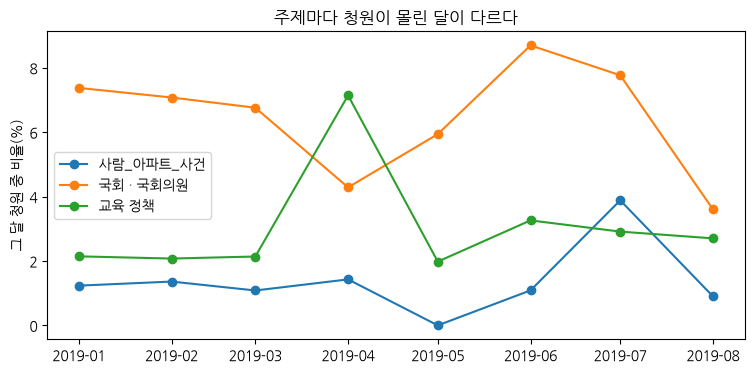

In [53]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in ["사람_아파트_사건", "국회 · 국회의원", "교육 정책"]:
    t = topic_id(name)
    if t is not None and t in share.columns:
        ax.plot(share.index, share[t] * 100, marker="o", label=name)
ax.set_ylabel("그 달 청원 중 비율(%)")
ax.set_title("주제마다 청원이 몰린 달이 다르다")
ax.legend()
plt.show()

In [62]:
recent = sample["begin"].dt.month >= 15
avg_agree = (sample["num_agree"] >= 100).mean() * 100

pri = topic_table().drop("이상치", errors="ignore")
pri["최근 3개월 %"] = sample[recent]["topic"].map(labels).value_counts(normalize=True) * 100
pri["앞 9개월 %"] = sample[~recent]["topic"].map(labels).value_counts(normalize=True) * 100
pri["증가 배율"] = pri["최근 3개월 %"] / pri["앞 9개월 %"]

pri["규모"] = pri["비율 %"].rank(ascending=False) <= 10
pri["관심"] = pri["동의 100 이상 %"] > avg_agree
pri["최근 증가"] = pri["증가 배율"] >= 1.2
pri["충족 수"] = pri[["규모", "관심", "최근 증가"]].sum(axis=1)
print(f"표본 전체의 동의 100 이상 비율: {avg_agree:.1f}%")
pri.sort_values(["충족 수", "비율 %"], ascending=False).round(2).head(100)

표본 전체의 동의 100 이상 비율: 8.4%


,청원 수,비율 %,동의 100 이상 %,최근 3개월 %,앞 9개월 %,증가 배율,규모,관심,최근 증가,충족 수
토픽 이름,,,,,,,,,,
사람_미세먼지_나라,607,6.1,8.9,NaN,6.07,NaN,True,True,False,2
사람_말_의원,384,3.8,8.9,NaN,3.84,NaN,True,True,False,2
외교 정책,354,3.5,11.0,NaN,3.54,NaN,True,True,False,2
여성가족부 · 성평등 (2),1219,12.2,8.3,NaN,12.19,NaN,True,False,False,1
환경 정책,871,8.7,7.8,NaN,8.71,NaN,True,False,False,1
국회 · 국회의원,701,7.0,7.6,NaN,7.01,NaN,True,False,False,1
여성가족부 · 성평등,597,6.0,8.4,NaN,5.97,NaN,True,False,False,1
국회 · 국회의원 (2),427,4.3,8.2,NaN,4.27,NaN,True,False,False,1
정부_사람_문재인,367,3.7,8.2,NaN,3.67,NaN,True,False,False,1


In [64]:
rows = []
for name, word in [("사람_미세먼지_나라", "건강"), ("교육 정책", "입시"),
                   ("사람_아파트_사건", "불안"), ("여성가족부 · 성평등", "사퇴")]:
    sub = sample[sample["topic"].map(labels) == name]
    if len(sub) == 0:
        print(f"이 실행에서는 「{name}」 토픽이 나오지 않아 건너뜁니다.")
        continue
    rows.append({"토픽": name, "단어": word,
                 "앞 9개월 %": sub.loc[~recent[sub.index], "doc"].str.contains(word).mean() * 100,
                 "최근 3개월 %": sub.loc[recent[sub.index], "doc"].str.contains(word).mean() * 100})
pd.DataFrame(rows).round(0)

,토픽,단어,앞 9개월 %,최근 3개월 %
0,사람_미세먼지_나라,건강,2.0,NaN
1,교육 정책,입시,1.0,NaN
2,사람_아파트_사건,불안,2.0,NaN
3,여성가족부 · 성평등,사퇴,1.0,NaN


In [65]:
new_topics, _ = topic_model.transform(new["nouns"].tolist(), embeddings=emb_new)
new["topic"] = new_topics

train_share = sample["topic"].map(labels).value_counts(normalize=True) * 100
def gap(topics):
    # 총변동 거리: 토픽마다 비율 차이의 절댓값을 더해 2로 나눈 값(%p)
    s = pd.Series(topics).map(labels).value_counts(normalize=True) * 100
    return train_share.sub(s, fill_value=0).abs().sum() / 2

print(f"총변동 거리, 학습 표본 대 새 청원 500건: {gap(new_topics):.1f}%p")
base_gaps = [gap(sample["topic"].sample(500, random_state=i)) for i in range(20)]
print(f"총변동 거리, 학습 표본 대 다시 추출한 500건(20번): 평균 {np.mean(base_gaps):.1f}%p, "
      f"범위 {min(base_gaps):.1f}～{max(base_gaps):.1f}%p")

cmp = pd.DataFrame({"학습 표본 %": train_share,
                    "새 청원 %": new["topic"].map(labels).value_counts(normalize=True) * 100}).fillna(0)
cmp.sort_values("학습 표본 %", ascending=False).round(1).head(8)

총변동 거리, 학습 표본 대 새 청원 500건: 16.9%p
총변동 거리, 학습 표본 대 다시 추출한 500건(20번): 평균 7.0%p, 범위 4.5～10.9%p


,학습 표본 %,새 청원 %
topic,,
이상치,28.9,37.0
여성가족부 · 성평등 (2),12.2,8.6
환경 정책,8.7,7.2
국회 · 국회의원,7.0,3.6
사람_미세먼지_나라,6.1,8.0
여성가족부 · 성평등,6.0,5.2
국회 · 국회의원 (2),4.3,4.2
사람_말_의원,3.8,3.8


In [66]:
SAVE_DIR = "petition_topic_model"
topic_model.save(SAVE_DIR, serialization="safetensors", save_ctfidf=True,
                 save_embedding_model="nlpai-lab/KURE-v1")
size_kb = sum(os.path.getsize(os.path.join(SAVE_DIR, f)) for f in os.listdir(SAVE_DIR)) / 1024
print(f"저장한 파일: {sorted(os.listdir(SAVE_DIR))}, 합계 {size_kb:.0f}KB")

저장한 파일: ['config.json', 'ctfidf.safetensors', 'ctfidf_config.json', 'topic_embeddings.safetensors', 'topics.json'], 합계 1738KB


In [67]:
loaded = BERTopic.load(SAVE_DIR, embedding_model=emb_model)
loaded_topics, _ = loaded.transform(new["nouns"].tolist(), embeddings=emb_new)
loaded_topics = np.array(loaded_topics)

print(f"학습한 모델의 이상치: {np.mean(np.array(new_topics) == -1):.1%}")
print(f"불러온 모델의 이상치: {np.mean(loaded_topics == -1):.1%}")
inside = np.array(new_topics) != -1
print(f"학습한 모델이 토픽을 정한 청원 중 같은 토픽: {np.mean(loaded_topics[inside] == np.array(new_topics)[inside]):.1%}")

Loading weights: 100%|██████████| 391/391 [00:01<00:00, 266.05it/s]


학습한 모델의 이상치: 37.0%
불러온 모델의 이상치: 11.8%
학습한 모델이 토픽을 정한 청원 중 같은 토픽: 81.9%


In [68]:
settings = {
    "데이터": "heegyu/korean-petitions, 2018-01～12 시작 청원",
    "정제": f"본문 빈 청원 · 제목과 본문이 같은 중복 청원 제외, 제목 + 본문 {MAX_LEN}자",
    "표본": f"{len(sample):,}건(random_state=0), 새 청원 {len(new)}건(random_state=1)",
    "임베딩 모델": "nlpai-lab/KURE-v1, normalize, max_seq_length 256",
    "임베딩 계산 장치": f"{device}" + (", 16비트(half)" if device == "cuda" else ", 32비트"),
    "UMAP": f"{umap_args}, random_state=0",
    "HDBSCAN": "min_cluster_size=50, euclidean, eom",
    "토픽 단어": f"Kiwi NNG · NNP, 사용자 사전 2개, 불용어 {len(STOP_WORDS)}개",
    "합치기": " / ".join(" + ".join(p) for p in merge_plan.values()),
    "이상치": "결과 정리는 재배정 전 비율, 재배정(c-tf-idf, 0.1)은 topic_re 열",
    "버전": f"bertopic {bertopic.__version__}",
}
pd.Series(settings, name="값").to_frame()

,값
데이터,"heegyu/korean-petitions, 2018-01～12 시작 청원"
정제,"본문 빈 청원 · 제목과 본문이 같은 중복 청원 제외, 제목 + 본문 150자"
표본,"10,000건(random_state=0), 새 청원 500건(random_state=1)"
임베딩 모델,"nlpai-lab/KURE-v1, normalize, max_seq_length 256"
임베딩 계산 장치,"cpu, 32비트"
UMAP,"{'n_neighbors': 15, 'n_components': 5, 'min_dist': 0.0, 'metric': 'cosine'}, random_st..."
HDBSCAN,"min_cluster_size=50, euclidean, eom"
토픽 단어,"Kiwi NNG · NNP, 사용자 사전 2개, 불용어 23개"
합치기,사람_말_미세먼지 + 미세먼지_정부_연금 / 법_초등학교_대리 + 입시 · 학교 교육 / 일본 · 독도 · 위안부 + 남북 관계 · 북한
이상치,"결과 정리는 재배정 전 비율, 재배정(c-tf-idf, 0.1)은 topic_re 열"
